# import libraries

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("Unemployment in India.csv")

print(df.shape)
df.head()

(768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


# Data cleaning

In [21]:
# 1. Clean column names (strip spaces, make short names)
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Region": "State",
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "LPR"
})

# 2. Check missing values and duplicates BEFORE dropping
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Drop empty rows and duplicates
df = df.dropna().drop_duplicates().reset_index(drop=True)

# 4. Clean text columns and fix the date format
df["State"] = df["State"].str.strip()
df["Area"] = df["Area"].str.strip()
df["Frequency"] = df["Frequency"].str.strip()
df["Date"] = pd.to_datetime(df["Date"].str.strip(), dayfirst=True)

# 5. Add helper columns
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Year"] = df["Date"].dt.year

print("\nCleaned shape:", df.shape)
df.info()

Missing values:
 State                28
Date                 28
Frequency            28
Unemployment_Rate    28
Employed             28
LPR                  28
Area                 28
dtype: int64

Duplicate rows: 27

Cleaned shape: (740, 10)
<class 'pandas.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   State              740 non-null    str           
 1   Date               740 non-null    datetime64[us]
 2   Frequency          740 non-null    str           
 3   Unemployment_Rate  740 non-null    float64       
 4   Employed           740 non-null    float64       
 5   LPR                740 non-null    float64       
 6   Area               740 non-null    str           
 7   Month              740 non-null    int32         
 8   Month_Name         740 non-null    str           
 9   Year               740 non-null    int32         
dt

# Exploration

In [3]:
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Number of states:", df["State"].nunique())
print("Areas:", df["Area"].unique())

df.describe()

Date range: 2019-05-31 to 2020-06-30
Number of states: 28
Areas: <ArrowStringArray>
['Rural', 'Urban']
Length: 2, dtype: str


,Date,Unemployment_Rate,Employed,LPR,Month,Year
count,740,740.000000,7.400000e+02,740.000000,740.000000,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122,6.390541,2019.418919
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000,1.000000,2019.000000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500,4.000000,2019.000000
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000,6.000000,2019.000000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000,9.000000,2020.000000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000,12.000000,2020.000000
std,NaN,10.721298,8.087988e+06,8.111094,3.235070,0.493716


In [4]:
# Average unemployment by state (top 10 highest)
state_avg = df.groupby("State")["Unemployment_Rate"].mean().sort_values(ascending=False)
print(state_avg.head(10))

# Rural vs Urban
print(df.groupby("Area")["Unemployment_Rate"].mean())

# Correlation
df[["Unemployment_Rate", "Employed", "LPR"]].corr()

State
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Unemployment_Rate, dtype: float64
Area
Rural    10.324791
Urban    13.166614
Name: Unemployment_Rate, dtype: float64


,Unemployment_Rate,Employed,LPR
Unemployment_Rate,1.000000,-0.222876,0.002558
Employed,-0.222876,1.000000,0.011300
LPR,0.002558,0.011300,1.000000


# Basic visualizations

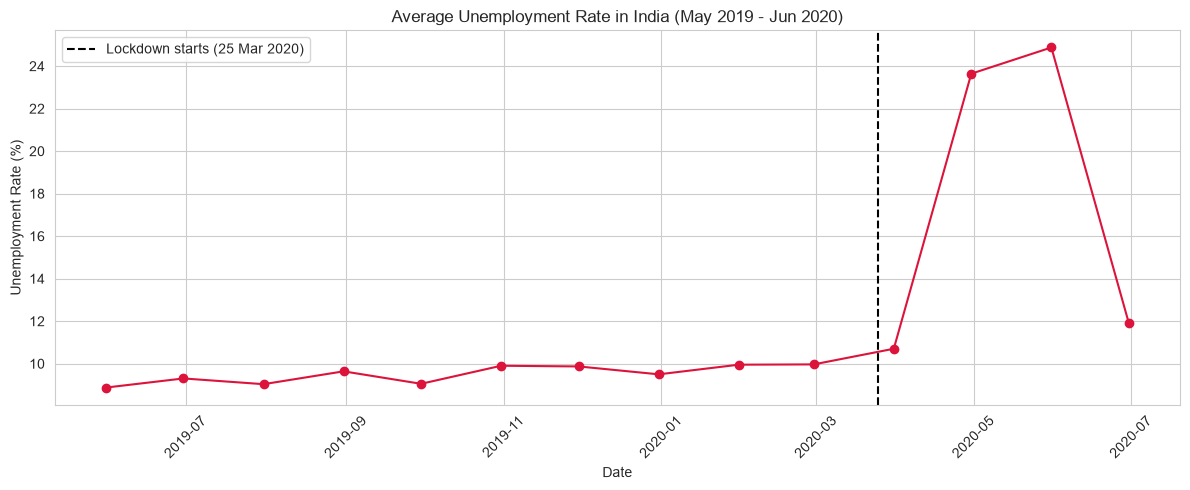

In [5]:
sns.set_style("whitegrid")

# 1. National trend over time
monthly = df.groupby("Date")["Unemployment_Rate"].mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker="o", color="crimson")
plt.axvline(pd.to_datetime("2020-03-25"), color="black", linestyle="--", label="Lockdown starts (25 Mar 2020)")
plt.title("Average Unemployment Rate in India (May 2019 - Jun 2020)")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

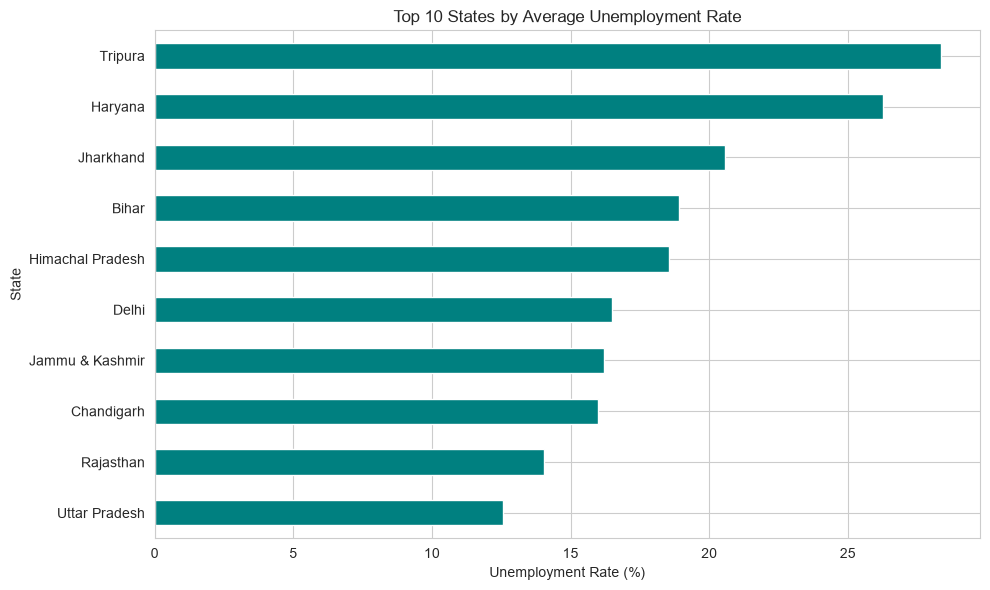

In [6]:
# 2. Top 10 states by average unemployment
plt.figure(figsize=(10, 6))
state_avg.head(10).sort_values().plot(kind="barh", color="teal")
plt.title("Top 10 States by Average Unemployment Rate")
plt.xlabel("Unemployment Rate (%)")
plt.tight_layout()
plt.show()

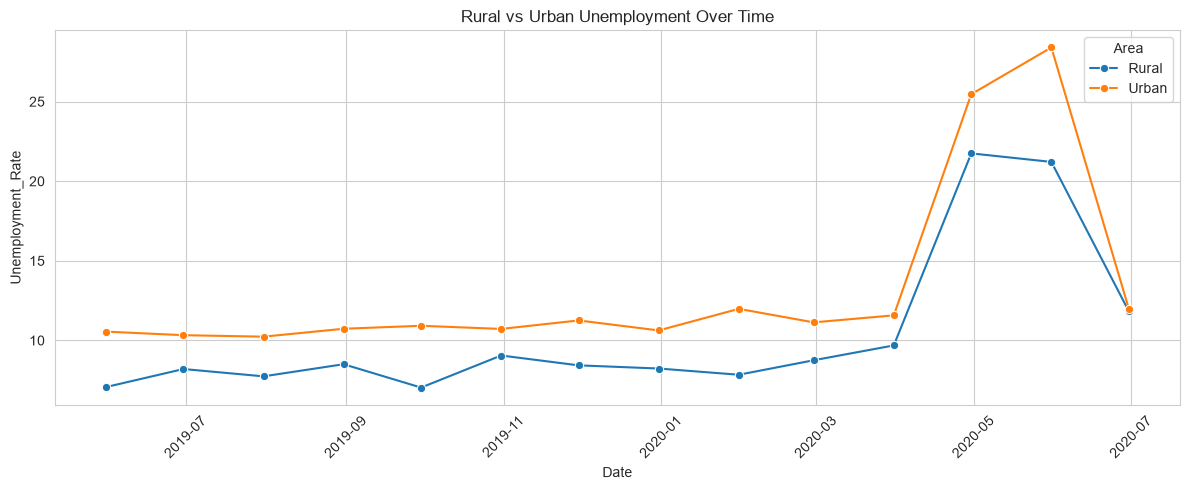

In [7]:
# 3. Rural vs Urban over time
plt.figure(figsize=(12, 5))
sns.lineplot(data=df, x="Date", y="Unemployment_Rate", hue="Area", marker="o", errorbar=None)
plt.title("Rural vs Urban Unemployment Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Define Covid periods and compare

Period
Pre-Covid                   9.51
Lockdown Onset (Mar)       10.70
Lockdown Peak (Apr-May)    24.26
Recovery (Jun)             11.90
Name: Unemployment_Rate, dtype: float64


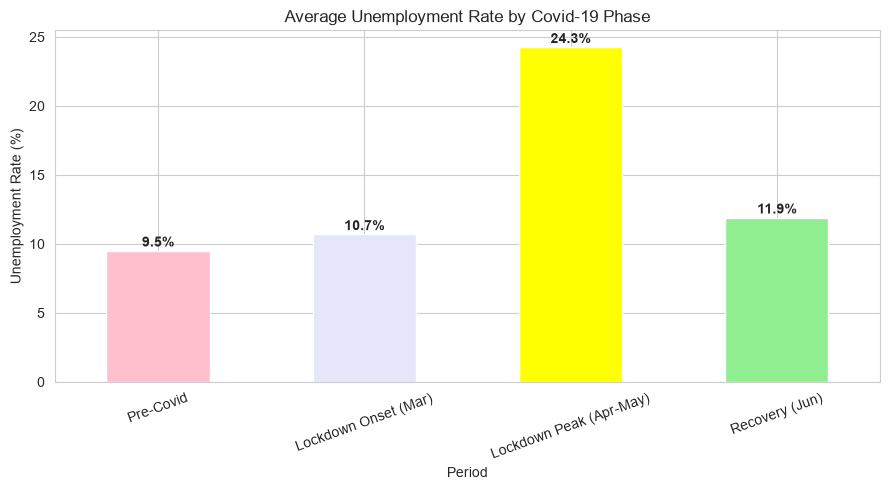

In [9]:
# Define periods
conditions = [
    df["Date"] < "2020-03-01",   # May 2019 - Feb 2020
    df["Date"] < "2020-04-01",   # March 2020 (lockdown began 25 Mar)
    df["Date"] < "2020-06-01",   # Apr - May 2020
]
labels = ["Pre-Covid", "Lockdown Onset (Mar)", "Lockdown Peak (Apr-May)"]
df["Period"] = np.select(conditions, labels, default="Recovery (Jun)")

order = ["Pre-Covid", "Lockdown Onset (Mar)", "Lockdown Peak (Apr-May)", "Recovery (Jun)"]

# Overall average per period
period_avg = df.groupby("Period")["Unemployment_Rate"].mean().reindex(order)
print(period_avg.round(2))

plt.figure(figsize=(9, 5))
ax = period_avg.plot(kind="bar", color=["pink", "lavender", "yellow", "lightgreen"])
for i, v in enumerate(period_avg):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontweight="bold")
plt.title("Average Unemployment Rate by Covid-19 Phase")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Area                     Rural  Urban
Period                               
Pre-Covid                 8.09  10.84
Lockdown Onset (Mar)      9.68  11.57
Lockdown Peak (Apr-May)  21.48  26.93
Recovery (Jun)           11.83  11.98


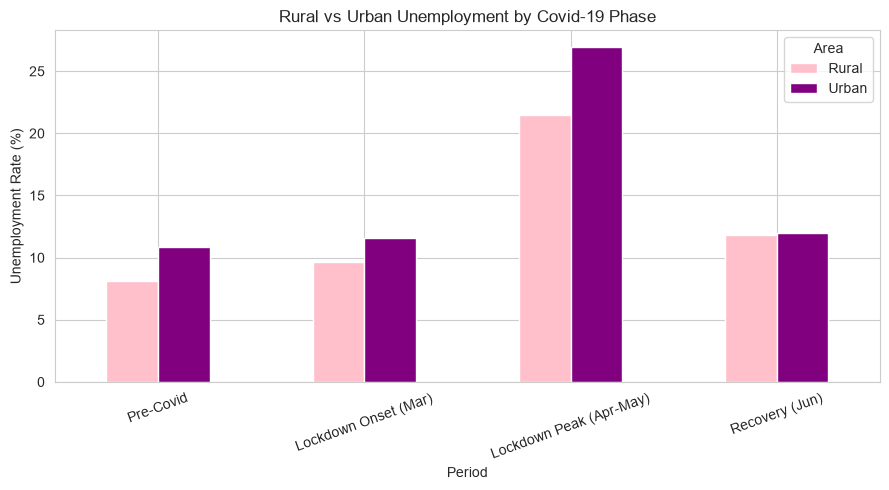

In [11]:
# Rural vs Urban by period
area_period = df.pivot_table(index="Period", columns="Area",
                             values="Unemployment_Rate", aggfunc="mean").reindex(order)
print(area_period.round(2))

area_period.plot(kind="bar", figsize=(9, 5), color=["pink", "purple"])
plt.title("Rural vs Urban Unemployment by Covid-19 Phase")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# State-wise Covid impact

Top 10 states by increase in unemployment:
                Pre_Covid   Peak  Increase
State                                     
Puducherry           1.59  75.42     73.82
Jharkhand           14.28  57.12     42.84
Tamil Nadu           2.84  40.85     38.02
Bihar               13.83  47.25     33.41
Karnataka            3.23  24.47     21.24
Haryana             22.94  40.30     17.36
Madhya Pradesh       4.74  21.85     17.11
Andhra Pradesh       5.04  21.99     16.95
Telangana            4.66  21.40     16.74
Kerala               6.99  21.45     14.46


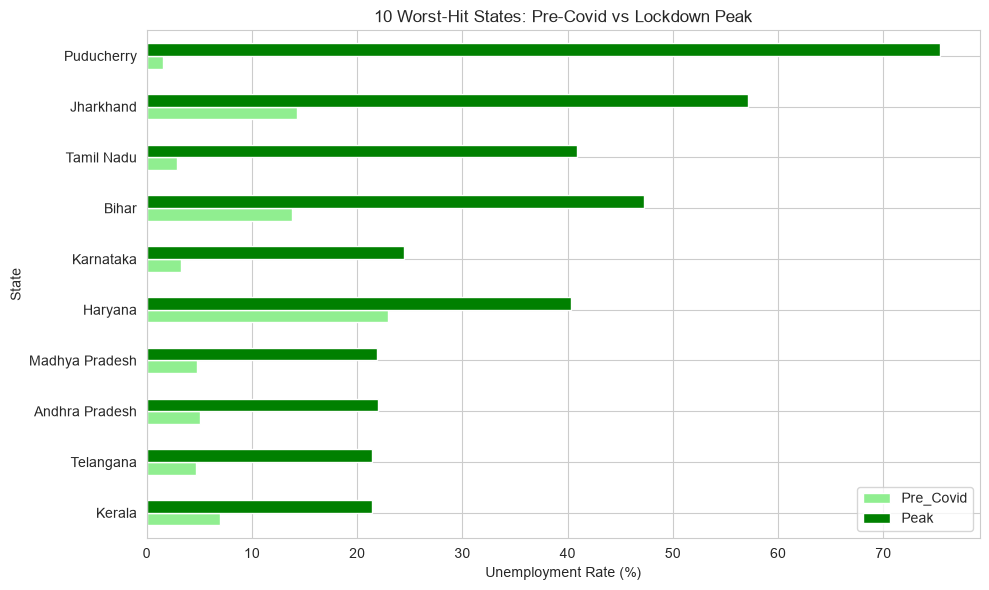

In [13]:
pre  = df[df["Period"] == "Pre-Covid"].groupby("State")["Unemployment_Rate"].mean()
peak = df[df["Period"] == "Lockdown Peak (Apr-May)"].groupby("State")["Unemployment_Rate"].mean()

impact = pd.DataFrame({"Pre_Covid": pre, "Peak": peak})
impact["Increase"] = impact["Peak"] - impact["Pre_Covid"]
impact = impact.sort_values("Increase", ascending=False).round(2)

print("Top 10 states by increase in unemployment:")
print(impact.head(10))

# Before vs peak for the 10 worst-hit states
top10 = impact.head(10).sort_values("Increase")
top10[["Pre_Covid", "Peak"]].plot(kind="barh", figsize=(10, 6), color=["lightgreen", "green"])
plt.title("10 Worst-Hit States: Pre-Covid vs Lockdown Peak")
plt.xlabel("Unemployment Rate (%)")
plt.tight_layout()
plt.show()

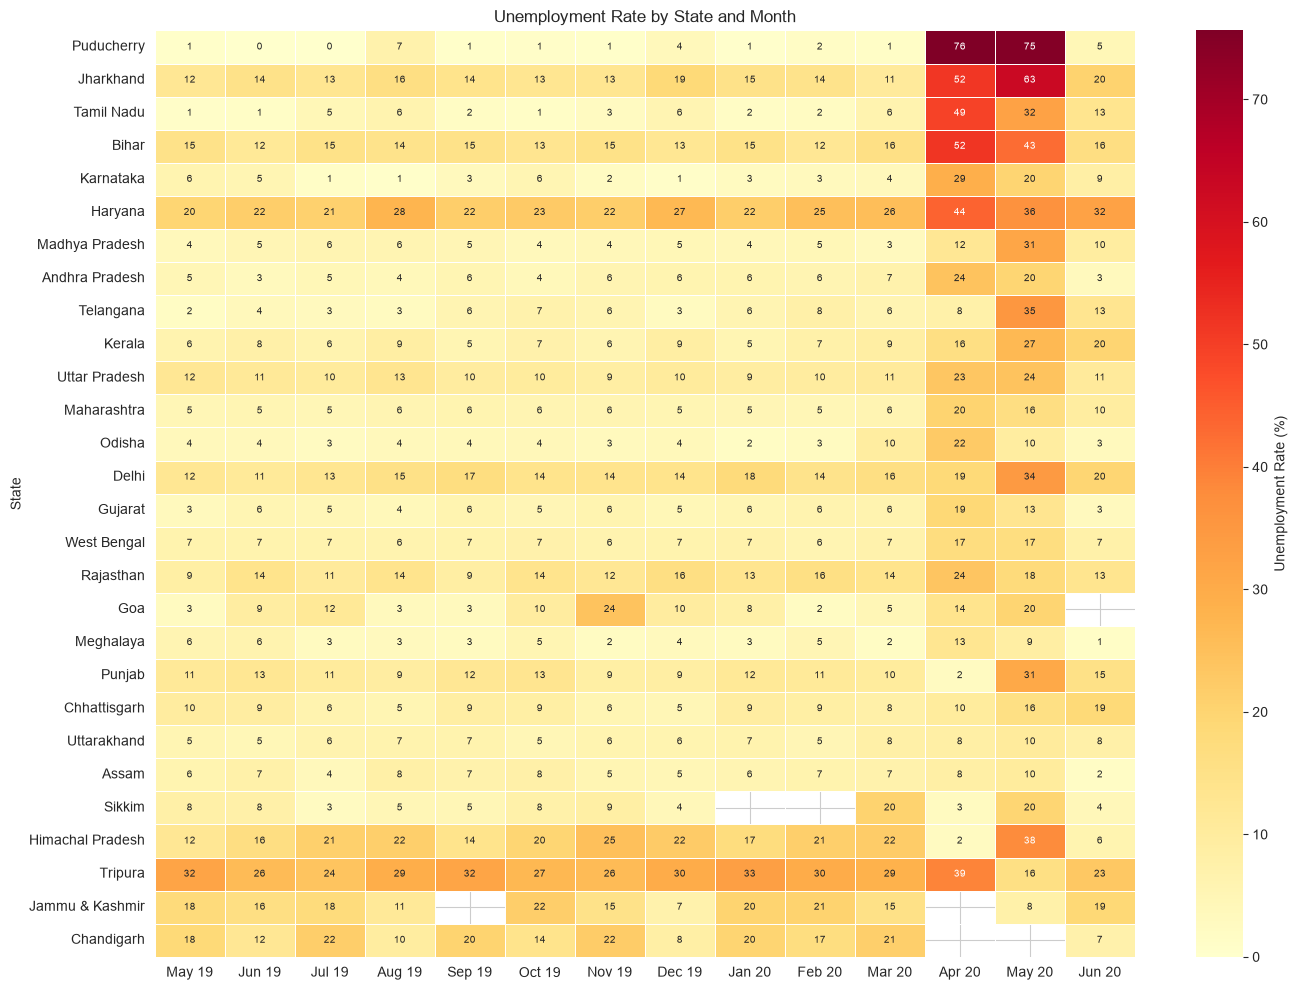

In [14]:
# Heatmap: state x month
pivot = df.pivot_table(index="State", columns="Date", values="Unemployment_Rate", aggfunc="mean")
pivot.columns = pivot.columns.strftime("%b %y")
pivot = pivot.loc[impact.index]   # sort rows by Covid impact

plt.figure(figsize=(14, 10))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7},
            linewidths=0.4, cbar_kws={"label": "Unemployment Rate (%)"})
plt.title("Unemployment Rate by State and Month")
plt.xlabel("")
plt.tight_layout()
plt.show()

# Jobs, participation, and seasonality

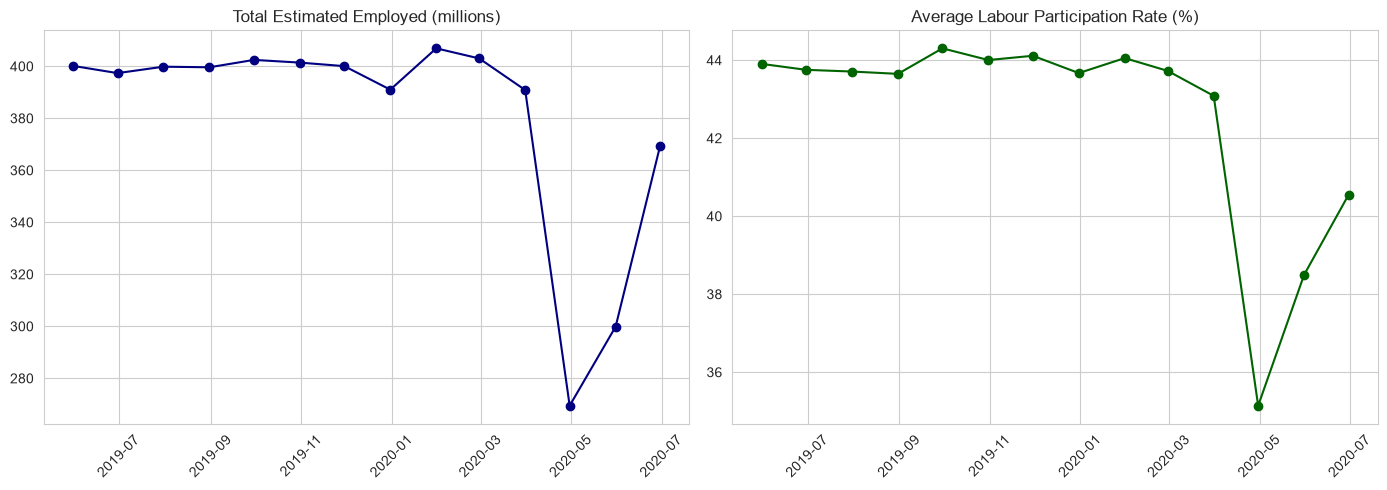

In [15]:
# Employed people and labour participation over time
employed = df.groupby("Date")["Employed"].sum() / 1e6   # in millions
lpr = df.groupby("Date")["LPR"].mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(employed.index, employed.values, marker="o", color="navy")
ax[0].set_title("Total Estimated Employed (millions)")
ax[0].tick_params(axis="x", rotation=45)

ax[1].plot(lpr.index, lpr.values, marker="o", color="darkgreen")
ax[1].set_title("Average Labour Participation Rate (%)")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

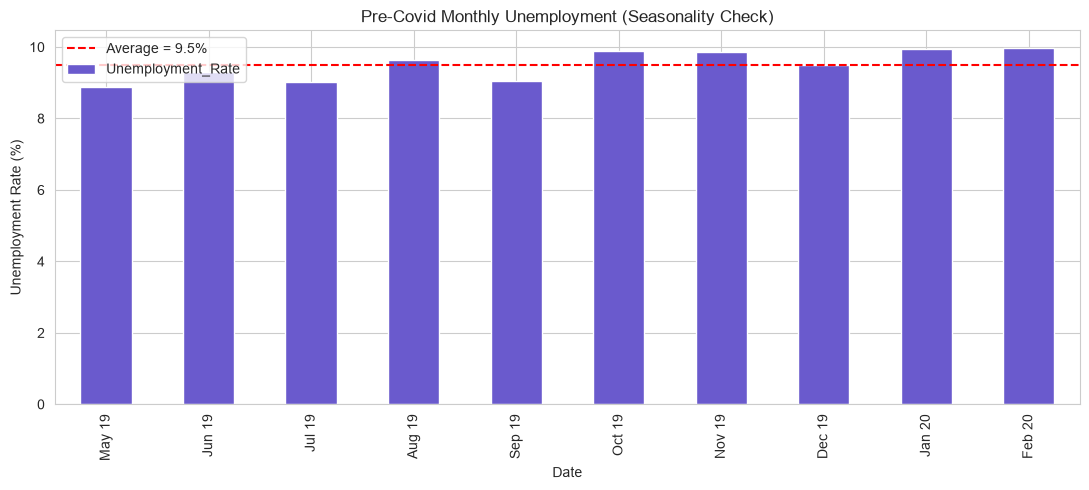

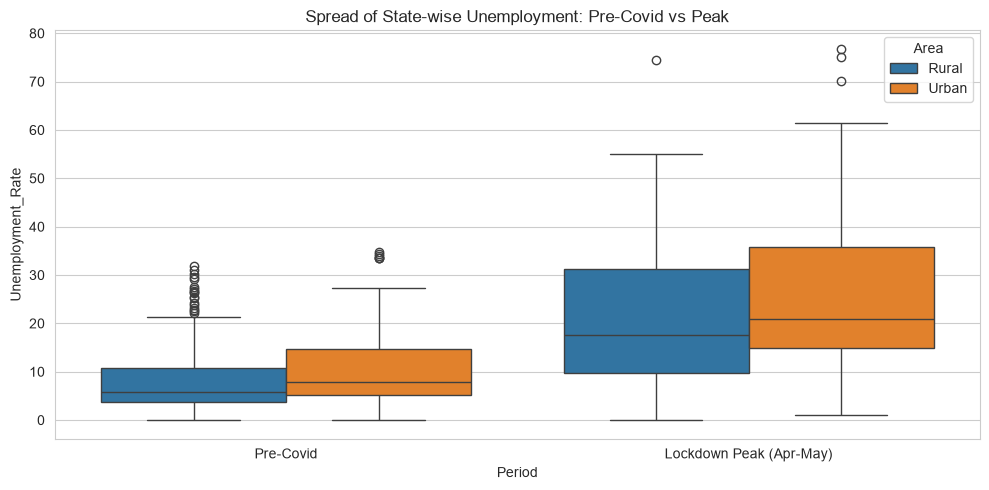

In [16]:
# Seasonality: use ONLY pre-Covid months so the lockdown doesn't distort it
pre_df = df[df["Period"] == "Pre-Covid"]

seasonal = pre_df.groupby("Date")["Unemployment_Rate"].mean()
seasonal.index = seasonal.index.strftime("%b %y")

plt.figure(figsize=(11, 5))
seasonal.plot(kind="bar", color="slateblue")
plt.axhline(seasonal.mean(), color="red", linestyle="--", label=f"Average = {seasonal.mean():.1f}%")
plt.title("Pre-Covid Monthly Unemployment (Seasonality Check)")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

# Boxplot: spread of state rates by area, pre-Covid vs peak
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[df["Period"].isin(["Pre-Covid", "Lockdown Peak (Apr-May)"])],
            x="Period", y="Unemployment_Rate", hue="Area")
plt.title("Spread of State-wise Unemployment: Pre-Covid vs Peak")
plt.tight_layout()
plt.show()

# Auto-generate key numbers for your report

In [22]:
pre_avg  = period_avg["Pre-Covid"]
peak_avg = period_avg["Lockdown Peak (Apr-May)"]
rec_avg  = period_avg["Recovery (Jun)"]
peak_month = monthly.idxmax()

print(f"Pre-Covid average unemployment : {pre_avg:.2f}%")
print(f"Peak average (Apr-May 2020)    : {peak_avg:.2f}%  (+{peak_avg - pre_avg:.2f} pts, {peak_avg/pre_avg:.1f}x)")
print(f"Highest month                  : {peak_month.strftime('%B %Y')} ({monthly.max():.2f}%)")
print(f"June 2020 recovery level       : {rec_avg:.2f}%")
print(f"Most affected state            : {impact.index[0]} (+{impact['Increase'].iloc[0]:.1f} pts)")
print(f"Least affected state           : {impact.index[-1]} ({impact['Increase'].iloc[-1]:+.1f} pts)")
print(f"Highest state value ever       : {df.loc[df['Unemployment_Rate'].idxmax(), ['State','Date','Unemployment_Rate']].tolist()}")

Pre-Covid average unemployment : 9.51%
Peak average (Apr-May 2020)    : 24.26%  (+14.75 pts, 2.6x)
Highest month                  : May 2020 (24.88%)
June 2020 recovery level       : 11.90%
Most affected state            : Puducherry (+73.8 pts)
Least affected state           : Chandigarh (+nan pts)
Highest state value ever       : ['Puducherry', Timestamp('2020-04-30 00:00:00'), np.float64(76.74)]
